# Titanic Survival Prediction

Predicting which passengers survived the Titanic from tabular passenger data.

**Workflow:** exploratory analysis → data cleaning → feature engineering → encoding → model comparison with cross-validation → overfitting analysis → final evaluation on a held-out test set.

**Dataset:** 891 passengers, 12 columns ([source](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv)).

## 1. Setup and data loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory data analysis

In [2]:
print(f"Overall survival rate: {df['Survived'].mean():.1%}")
print(f"Majority-class baseline (predict 'did not survive' for everyone): {1 - df['Survived'].mean():.1%}")

Overall survival rate: 38.4%
Majority-class baseline (predict 'did not survive' for everyone): 61.6%


In [3]:
df.groupby(["Pclass", "Sex"])["Survived"].mean().unstack().round(3)

Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


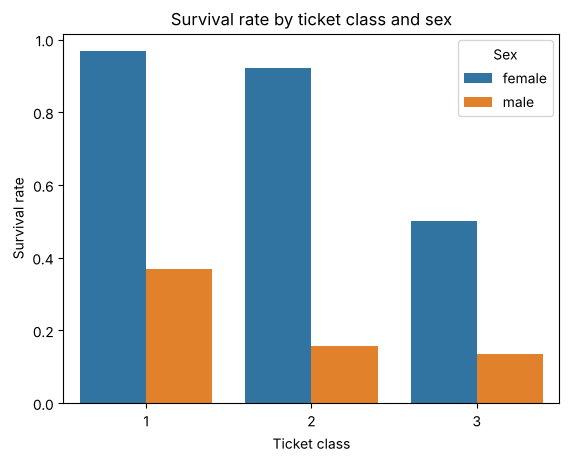

In [4]:
ax = sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
ax.set(title="Survival rate by ticket class and sex", xlabel="Ticket class", ylabel="Survival rate")
plt.show()

Sex and ticket class are the strongest signals: women and first-class passengers were far more likely to survive.

In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 3. Data cleaning

| Column | Missing | Decision |
|---|---|---|
| `Cabin` | 687 (77%) | Drop the column: too sparse to be useful |
| `Age` | 177 (20%) | Fill with the median (robust to outliers) |
| `Embarked` | 2 | Fill with the most frequent port |

In [6]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])
assert df.drop(columns=["Name", "Ticket"]).isnull().sum().sum() == 0

## 4. Feature engineering: passenger title

Names follow the pattern `"Surname, Title. First names"`. The title carries information that `Sex` and `Age` alone miss: **Master** was used for boys, who survived far more often than adult men (**Mr**). Rare titles (1–7 passengers each) are grouped into `Rare` to avoid the model memorising single cases.

In [7]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False)
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df.loc[~df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"
df.groupby("Title")["Survived"].agg(["mean", "count"]).round(3)

,mean,count
Title,,
Master,0.575,40
Miss,0.703,185
Mr,0.157,517
Mrs,0.794,126
Rare,0.348,23


## 5. Encoding

- `Sex`: male = 0, female = 1
- `Embarked`, `Title`: one-hot encoding (one 0/1 column per category, so no artificial order is implied)

In [8]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked", "Title"], dtype=int)

BASE_FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
                 "Embarked_C", "Embarked_Q", "Embarked_S"]
TITLE_FEATURES = ["Title_Master", "Title_Miss", "Title_Mr", "Title_Mrs", "Title_Rare"]
ALL_FEATURES = BASE_FEATURES + TITLE_FEATURES

X = df[ALL_FEATURES]
y = df["Survived"]

## 6. Train / test split

20% of passengers are held out and used **only once**, for the final evaluation. All model selection below uses 5-fold cross-validation on the training set.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {len(X_train)} passengers, test: {len(X_test)} passengers")

def cv(model, cols):
    scores = cross_val_score(model, X_train[cols], y_train, cv=5)
    return scores.mean(), scores.std()

Train: 712 passengers, test: 179 passengers


## 7. Model comparison (5-fold cross-validation on the training set)

In [10]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest (default depth)": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost (default)": XGBClassifier(n_estimators=100, random_state=42),
}
rows = []
for name, model in candidates.items():
    for label, cols in [("base features", BASE_FEATURES), ("+ title", ALL_FEATURES)]:
        mean, std = cv(model, cols)
        rows.append({"model": name, "features": label, "cv_accuracy": round(mean, 3), "std": round(std, 3)})
pd.DataFrame(rows).pivot(index="model", columns="features", values="cv_accuracy")

features,+ title,base features
model,,
Logistic Regression,0.820,0.795
Random Forest (default depth),0.801,0.796
XGBoost (default),0.795,0.799


The title feature gives a clear gain to Logistic Regression, which looks at each feature independently. Tree-based models gain less because they can already combine other columns (e.g. male + travelling with parents) to approximate the same information.

## 8. Overfitting and tree depth

Unrestricted trees memorise the training data. Limiting `max_depth` trades training accuracy for better generalisation.

In [11]:
depths = [2, 3, 4, 5, 6, 8, None]
rows = []
for d in depths:
    rf = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42)
    mean, std = cv(rf, ALL_FEATURES)
    train_acc = rf.fit(X_train, y_train).score(X_train, y_train)
    rows.append({"max_depth": str(d), "train_accuracy": round(train_acc, 3), "cv_accuracy": round(mean, 3), "std": round(std, 3)})
depth_df = pd.DataFrame(rows)
depth_df

,max_depth,train_accuracy,cv_accuracy,std
0,2,0.796,0.794,0.018
1,3,0.827,0.816,0.019
2,4,0.838,0.817,0.021
3,5,0.855,0.816,0.028
4,6,0.868,0.816,0.024
5,8,0.916,0.816,0.022
6,None,0.983,0.801,0.054


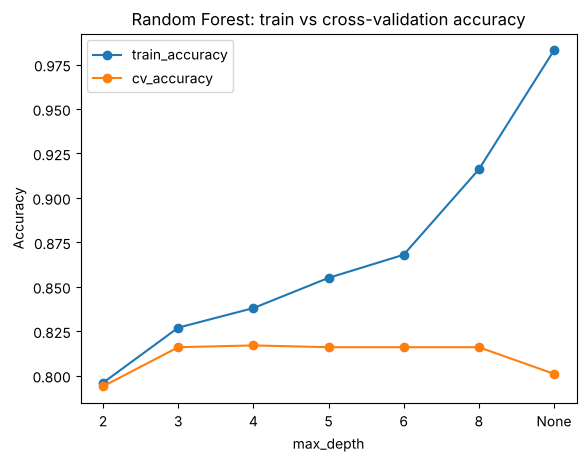

In [12]:
ax = depth_df.plot(x="max_depth", y=["train_accuracy", "cv_accuracy"], marker="o")
ax.set(title="Random Forest: train vs cross-validation accuracy", xlabel="max_depth", ylabel="Accuracy")
plt.show()

Training accuracy keeps rising with depth, while cross-validation accuracy plateaus in the middle range and drops for unlimited depth: the gap is overfitting.

## 9. Final model and held-out evaluation

Logistic Regression with the title feature performs on par with the tuned Random Forest in cross-validation, and is simpler and easier to interpret, so it is selected as the final model. It is trained on the full training set and evaluated **once** on the held-out test set.

In [13]:
final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Baseline:      {1 - y_test.mean():.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

Test accuracy: 0.838
Baseline:      0.615

                 precision    recall  f1-score   support

Did not survive       0.85      0.90      0.87       110
       Survived       0.82      0.74      0.78        69

       accuracy                           0.84       179
      macro avg       0.83      0.82      0.83       179
   weighted avg       0.84      0.84      0.84       179



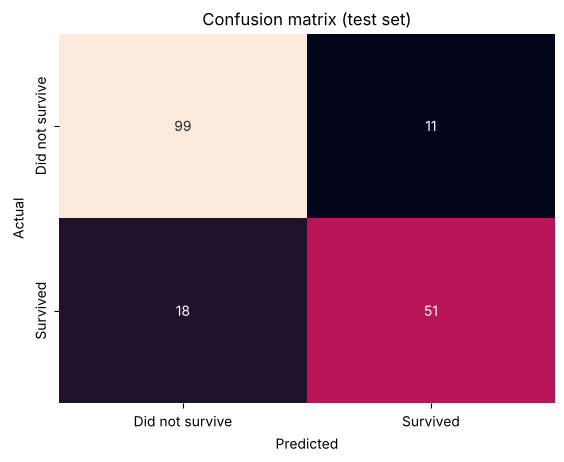

In [14]:
cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt="d", cbar=False,
                 xticklabels=["Did not survive", "Survived"], yticklabels=["Did not survive", "Survived"])
ax.set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")
plt.show()

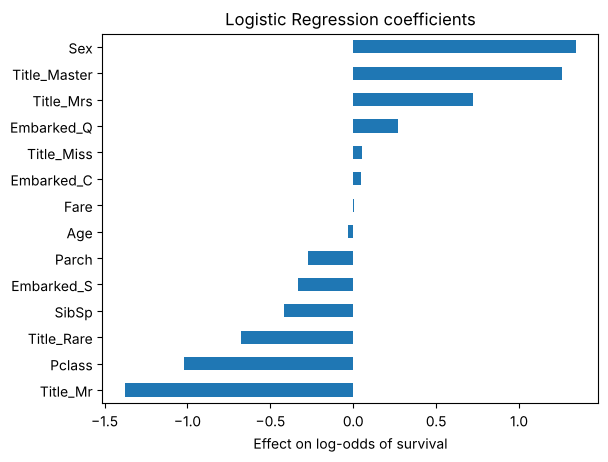

In [15]:
coef = pd.Series(final_model.coef_[0], index=ALL_FEATURES).sort_values()
ax = coef.plot(kind="barh")
ax.set(title="Logistic Regression coefficients", xlabel="Effect on log-odds of survival")
plt.show()

## 10. Conclusions

- A simple majority-class baseline reaches ~62%; all models clearly beat it.
- Feature engineering (passenger title) helped the linear model more than any hyperparameter change helped the trees.
- Unrestricted tree models overfit (near-perfect training accuracy, lower validation accuracy); limiting depth closes the gap.
- Differences smaller than the cross-validation standard deviation were treated as ties, and the simpler model was preferred.